Importing all datasets with noise column enabled...
Training set shape (excluding noise feature): (5364, 8)
Holdout test set shape: (1341, 8)

Training final soft-voting ensemble on X_train...
Training complete!

=== NOISE ROBUSTNESS EVALUATION ON TEST SUBSETS ===
[noiseless] Samples:  267 | Macro F1: 0.9967 | Normal precision: 1.0000
[50db] Samples:  249 | Macro F1: 0.9920 | Normal precision: 1.0000
[40db] Samples:  271 | Macro F1: 0.9960 | Normal precision: 1.0000
[30db] Samples:  284 | Macro F1: 0.9858 | Normal precision: 0.9268
[20db] Samples:  270 | Macro F1: 0.9496 | Normal precision: 0.9130


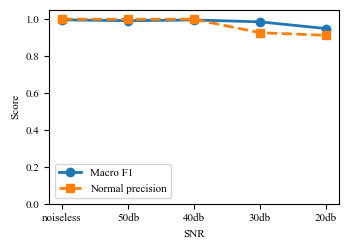

In [4]:
import matplotlib.pyplot as plt
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman"],
    "font.size": 7,
    "axes.labelsize": 8,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
    "figure.titlesize": 9,
})
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.metrics import f1_score, precision_score
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

from import_folder import import_all_noiselevel_data

# -----------------------------------------------------------------------------
# 1. Data Import (Including Noise Column)
# -----------------------------------------------------------------------------
noise_folders = [
    "SNR_noiseless",
    "SNR_50db",
    "SNR_40db",
    "SNR_30db",
    "SNR_20db",
]

print("Importing all datasets with noise column enabled...")
df_all = import_all_noiselevel_data(noise_folders, add_noise_column=True)

# -----------------------------------------------------------------------------
# 2. Combined Train-Test Split Across All Noise Levels
# -----------------------------------------------------------------------------
# Separate raw features (which include the noise identifier column), target labels, and class targets
X_raw = df_all.drop(columns=["label"])
y = df_all["label"]

# Random 80/20 train-test split (unstratified across noise levels, meaning test split sizes will naturally vary)
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw, y, test_size=0.20, random_state=42, stratify=y
)

# -----------------------------------------------------------------------------
# 3. Strip Noise Column from Training Features (Blind Training)
# -----------------------------------------------------------------------------
# Note: Adjust 'noise_level' if your custom import function names the column differently (e.g., 'noise')
noise_col_name = "noise_level"

# Drop the noise identifier from training features so models never learn it
X_train = X_train_raw.drop(columns=[noise_col_name])

# For the test set, drop it from features but save it separately to filter test subsets later
X_test = X_test_raw.drop(columns=[noise_col_name])
test_noise_labels = X_test_raw[noise_col_name]

print(f"Training set shape (excluding noise feature): {X_train.shape}")
print(f"Holdout test set shape: {X_test.shape}\n")

# -----------------------------------------------------------------------------
# 4. Initialize Models with Your Optimized Hyperparameters
# -----------------------------------------------------------------------------
dt_best = DecisionTreeClassifier(
    max_depth=12,
    min_samples_split=6,
    min_samples_leaf=3,
    criterion="gini",
    random_state=42,
)

rf_best = RandomForestClassifier(
    n_estimators=316,
    max_depth=19,
    min_samples_split=18,
    min_samples_leaf=1,
    criterion="log_loss",
    random_state=42,
    n_jobs=-1,
)

mlp_best = MLPClassifier(
    hidden_layer_sizes=(256,),
    activation="relu",
    solver="adam",
    alpha=0.001,
    learning_rate_init=0.003,
    max_iter=1000,
    random_state=42,
    early_stopping=True,
)

# Soft-Voting Ensemble (Bagged Model)
voting_ensemble = VotingClassifier(
    estimators=[("dt", dt_best), ("rf", rf_best), ("mlp", mlp_best)],
    voting="soft",
    n_jobs=-1,
)

# Full Pipeline with Feature Scaling
bagged_pipeline = Pipeline(
    [
        ("scaler", StandardScaler()),
        ("classifier", voting_ensemble),
    ]
)

# -----------------------------------------------------------------------------
# 5. Train the Ensemble Exclusively on X_train
# -----------------------------------------------------------------------------
print("Training final soft-voting ensemble on X_train...")
bagged_pipeline.fit(X_train, y_train)
print("Training complete!\n")

# -----------------------------------------------------------------------------
# 6. Evaluate Test Splits Separated by Noise Level
# -----------------------------------------------------------------------------
robustness_results = []

print("=== NOISE ROBUSTNESS EVALUATION ON TEST SUBSETS ===")

NORMAL_LABEL = 0

def normal_precision(y_true, y_pred):
    return precision_score(y_true, y_pred, labels=[NORMAL_LABEL], average="macro", zero_division=0)

for noise_lvl in noise_folders:
    # Filter test indices corresponding to the current noise level
    mask = test_noise_labels == noise_lvl
    if not mask.any():
        continue

    X_test_sub = X_test[mask]
    y_test_sub = y_test[mask]

    # Predict using the trained blind pipeline
    y_pred_sub = bagged_pipeline.predict(X_test_sub)

    # Compute Macro F1-Score & Normal Class Precision
    macro_f1 = f1_score(y_test_sub, y_pred_sub, average="macro", zero_division=0)

    normal_precision_score = normal_precision(y_test_sub, y_pred_sub)

    robustness_results.append(
        {
            "SNR": noise_lvl.removeprefix("SNR_"),
            "Samples": len(y_test_sub),
            "Macro F1": macro_f1,
            "Normal precision": normal_precision_score,
        }
    )

    print(
        f"[{noise_lvl.removeprefix('SNR_')}] Samples: {len(y_test_sub):4d} | Macro F1:"
        f" {macro_f1:.4f} | Normal precision: {normal_precision_score:.4f}"
    )

robustness_df = pd.DataFrame(robustness_results)

# -----------------------------------------------------------------------------
# 7. Plot Performance Curves Across Noise Levels
# -----------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(3.5, 2.5))

ax.plot(
    robustness_df["SNR"],
    robustness_df["Macro F1"],
    marker="o",
    linewidth=2,
    color="tab:blue",
    label="Macro F1",
)
ax.plot(
    robustness_df["SNR"],
    robustness_df["Normal precision"],
    marker="s",
    linewidth=2,
    linestyle="--",
    color="tab:orange",
    label="Normal precision",
)

ax.set_xlabel("SNR")
ax.set_ylabel("Score")
ax.set_ylim(0.0, 1.05)
ax.legend(loc="lower left")

plt.tight_layout()
fig.savefig("soft_voting_ensemble_robustness.pdf", bbox_inches="tight")
plt.show()